# Класифікатор тональності відгуків: FastText + BiGRU/BiLSTM (скаляр + нейтральна смуга)

Ноутбук від сирого датасету до **переносного артефакту моделі**.

| # | Розділ | Результат |
|---|--------|-----------|
| 1 | Налаштування та конфіг | усі параметри в одному місці |
| 2 | Утиліти | єдина `clean_text`, правило класів, `predict_texts_generic` |
| 3 | Дані | очищений датасет, відновлені заперечення |
| 4 | Наші фрази | рукописні пари + шаблони (train) і `hand_test` (лише тест) |
| 5 | Судді | три трансформери голосують -> мітки (кеш за текстом) |
| 6 | Фінальні мітки | наші мітки перекривають голоси; `labeled.csv` |
| 7 | Спліт, словник, DataLoader'и | наші фрази лише в train |
| 8 | Ембедінги | FastText для словника train |
| 9 | Модель | BiGRU/BiLSTM + self-attention + attention-пулінг, один логіт |
| 10 | Тренування | вибір епохи за правилом нейтральності |
| 11 | Правило класів | нейтральна смуга `[NEUTRAL_LO, NEUTRAL_HI)` |
| 12 | Оцінка | val, test, діагностика, `hand_test`, помилки |
| 13 | Експорт | `artifacts/`: модель, конфіг, мітки, метрики; перевірка завантаженням |
| 14 | Інтерактив (необов'язково) | вердикт і SHAP для довільних фраз |

**Клас** визначається за p = sigmoid(логіт): `p < NEUTRAL_LO` негатив, `p >= NEUTRAL_HI` позитив, між ними нейтральний.
Щоб запустити все, виконай клітинки зверху вниз.

## 1. Налаштування та конфіг

In [1]:
!pip install -q gensim transformers umap-learn kagglehub

import os, re, glob, json, random, shutil, warnings
from collections import Counter
from copy import deepcopy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             roc_auc_score, precision_recall_fscore_support)

warnings.filterwarnings("ignore", category=UserWarning)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)

Device: cuda | torch 2.14.1+cu130


In [2]:
# ====================== КОНФІГ: усі параметри тут ======================
SEED = 42

# ---------- шляхи ----------
TEXT_COL = "cleaned_review"
CSV_NAME = "cleaned_reviews.csv"       # колонки sentiments / review_score НЕ використовуються
KAGGLE_DATASET = "danielihenacho/amazon-reviews-dataset"    # порожньо = шукати файл локально
OUT_DIR = "artifacts"                  # сюди пишемо все, що забираємо: модель, конфіг, мітки, метрики
USE_DRIVE = False                      # True -> змонтувати Google Drive, щоб кеш суддів пережив перезапуск
CACHE_DIR = "."                        # якщо USE_DRIVE: "/content/drive/MyDrive/mlops_review_clf"

# ---------- передобробка тексту ----------
RESTORE_NEG = True                     # doesn -> does not (датасет втратив "not" при розбитті апострофа)
NEG_FRAGMENTS = {"doesn": "does not", "didn": "did not", "isn": "is not", "wasn": "was not", "aren": "are not",
                 "weren": "were not", "couldn": "could not", "wouldn": "would not", "shouldn": "should not",
                 "hasn": "has not", "haven": "have not", "hadn": "had not", "don": "do not", "won": "will not",
                 "mustn": "must not", "needn": "need not"}

# ---------- наші фрази ----------
USE_HAND = True                        # додавати рукописні пари та шаблонні фрази в train
USE_NEW_FRAMES = True                  # рамки з flaws/defects/broke у всіх класах (проти шортката на слово)
HAND_REPEAT = 3                        # скільки разів дублювати рукописні в train
SYN_NOUNS_PER_FRAME = 12               # шаблонних товарів на рамку (менше = менше синтетики)
HAND_TEST_PAIRS = {21, 22, 23, 24, 25, 34, 35}          # пари лише для тесту
SYN_TEST_NOUNS = {"speaker", "jacket", "printer", "lamp"}

# ---------- судді (три трансформери голосують) ----------
TEACHER_MODELS = {
    "q1": "cardiffnlp/twitter-roberta-base-sentiment-latest",   # P(pos)/(P(pos)+P(neg))
    "q2": "siebert/sentiment-roberta-large-english",            # бінарна: P(POSITIVE)
    "q3": "nlptown/bert-base-multilingual-uncased-sentiment",   # зірки: P(4-5)/(P(1-2)+P(4-5))
}
TEACHER_CACHE_NAME = "teacher_scores.csv"
CACHE_COL = {"q1": "q1", "q2": "q2", "q3": "q3_v2"}     # q3_v2: нова формула q3

LABEL_MODE = "vote"         # "vote": кожен суддя ставить клас, перемагає більшість; усі три різні -> neutral
                            # "mean": жорстка мітка за ентропією середнього q̄
                            # "soft": вчимося на q̄ як на м'якому таргеті
VOTE_H_THR = 0.80           # суддя каже "neutral", якщо H(q_i) >= порога (0.81 ~ q in (0.25, 0.75))
MEAN_H_THR = 0.80

# ---------- класи та цілі ----------
CLASSES = ["negative", "neutral", "positive"]
SCALAR_TARGET = {0: 0.0, 1: 0.5, 2: 1.0}     # клас -> ціль для BCE
SMOOTH = 0.05                                 # 0->0.05, 0.5->0.5, 1->0.95

# ---------- підготовка ----------
MAX_LEN, MIN_FREQ, BATCH_SIZE = 128, 2, 64
TEST_SIZE, VAL_SIZE = 0.15, 0.15
PAD_IDX, UNK_IDX = 0, 1
EMB_NAME, EMB_DIM = "fasttext-wiki-news-subwords-300", 300

# ---------- модель ----------
RNN_TYPE = "gru"            # "gru" | "lstm"
HIDDEN, NUM_LAYERS = 256, 2
HEAD_DIMS = (256, 128, 64)
EMB_DROPOUT, RNN_DROPOUT, HEAD_DROPOUT = 0.2, 0.2, 0.3
NORM = "batch"              # норма в голові: "batch" | "layer" | None
FREEZE_EMB = True
EMB_NORM, OUT_NORM, POOL_NORM = True, True, True     # LayerNorm на ембедінгах / виході RNN / зібраному векторі
SELF_ATTN, ATTN_POOL = True, True                    # self-attention поверх RNN / attention-пулінг
ATTN_HEADS, ATTN_DROPOUT = 4, 0.1                    # 2*HIDDEN має ділитись на ATTN_HEADS

# ---------- тренування ----------
EPOCHS, LR, WEIGHT_DECAY, CLIP_NORM = 30, 1e-3, 5e-2, 1.0
PATIENCE, MIN_DELTA = 5, 0.002
WEIGHT_POWER = 1.0          # 1.0 = повні ваги класів, 0.5 = sqrt, 0 = без ваг

# ---------- правило нейтральності ----------
NEUTRAL_LO, NEUTRAL_HI = 0.15, 0.60     # p < LO негатив, p >= HI позитив, між ними нейтральний
RULE_MODE = "fixed"                     # "fixed": беремо межі вище; "tuned": підбір на val за macro-F1
SELECT_RULE = {"type": "asym", "lo": NEUTRAL_LO, "hi": NEUTRAL_HI}    # за ним обираємо найкращу епоху

# ---------- вихід ----------
ARTIFACT_NAME = "sentiment_rnn.pt"

# ---------- необов'язкове ----------
RUN_UMAP = False            # UMAP-візуалізація представлень (повільно)
INTERACTIVE = False         # клітинка вердикту / SHAP для власних фраз

# [smoke-override-point]

## 2. Утиліти
Одне визначення кожної функції: ті самі `clean_text`, `assign_classes` і `predict_texts_generic` підуть у `src/`.

In [3]:
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
TEACHER_CACHE = os.path.join(CACHE_DIR, TEACHER_CACHE_NAME)


def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()


# ---------- текст ----------
def restore_negation(t):
    # датасет розбив doesn't -> "doesn" (апостроф і t втрачено): повертаємо явне "not"
    return " ".join(NEG_FRAGMENTS.get(w, w) for w in str(t).split())


def clean_text(s):
    # сирий текст -> формат датасету: нижній регістр, лише літери, апостроф розбиває слово,
    # односимвольні токени геть (крім "i"), далі відновлення заперечень
    toks = [w for w in re.sub(r"[^a-z]+", " ", str(s).lower()).split() if len(w) > 1 or w == "i"]
    t = " ".join(toks)
    return restore_negation(t) if RESTORE_NEG else t


# ---------- ентропія та правило класів ----------
def binary_entropy(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-7, 1 - 1e-7)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


def entropy_to_p(thr):
    g = np.linspace(1e-7, 0.5, 200001)
    return float(g[min(np.searchsorted(binary_entropy(g), thr), len(g) - 1)])


def assign_classes(p, rule):
    # rule: {"type": "asym", "lo": a, "hi": b} або {"type": "entropy", "thr": t}
    p = np.asarray(p)
    if rule["type"] == "entropy":
        pred = np.where(p >= 0.5, 2, 0)
        pred[binary_entropy(p) >= rule["thr"]] = 1
        return pred
    pred = np.ones(len(p), dtype=int)
    pred[p < rule["lo"]] = 0
    pred[p >= rule["hi"]] = 2
    return pred


def rule_bounds(rule):
    if rule["type"] == "entropy":
        lo = entropy_to_p(rule["thr"])
        return lo, 1 - lo
    return rule["lo"], rule["hi"]


def describe_rule(rule):
    lo, hi = rule_bounds(rule)
    if rule["type"] == "entropy":
        return f"H(p) >= {rule['thr']:.2f} -> neutral, тобто p in ({lo:.2f}, {hi:.2f})"
    return f"p < {lo:.3f} -> neg, p >= {hi:.3f} -> pos, між ними neutral"


# ---------- голосування суддів ----------
def majority_vote(votes):
    # votes: [N, 3]. Більшість (2+ з 3) перемагає; усі три різні -> neutral
    counts = np.stack([(votes == c).sum(1) for c in range(3)], axis=1)
    return np.where(counts.max(1) >= 2, counts.argmax(1), 1)


def vote_bucket(votes):
    n_distinct = np.array([len(set(v)) for v in votes])
    return np.select([n_distinct == 1, n_distinct == 2], ["unanimous", "majority"], default="split")


# ---------- інференс (однаковий у ноутбуці та в src/predict.py) ----------
@torch.no_grad()
def predict_texts_generic(model, stoi, texts, max_len, dev, batch=256):
    # texts мають бути вже очищені (clean_text)
    model.eval()
    ids = [torch.tensor([stoi.get(w, UNK_IDX) for w in t.split()[:max_len]] or [UNK_IDX], dtype=torch.long)
           for t in texts]
    out = []
    for i in range(0, len(ids), batch):
        b = ids[i:i + batch]
        lens = torch.tensor([len(s) for s in b], dtype=torch.long)
        x = pad_sequence(b, batch_first=True, padding_value=PAD_IDX)
        out.append(torch.sigmoid(model(x.to(dev), lens)).cpu())
    return torch.cat(out).numpy()

## 3. Дані
Завантаження (локально або з Kaggle), унікальні тексти, відновлення заперечень.

In [4]:
def local_csv():
    cands = []
    if "path" in globals():
        cands.append(os.path.join(path, CSV_NAME))
    cands += [CSV_NAME, os.path.join("/content", CSV_NAME)]
    cands += glob.glob(f"/content/**/{CSV_NAME}", recursive=True)
    cands += glob.glob(f"/kaggle/**/{CSV_NAME}", recursive=True)
    return next((c for c in cands if os.path.exists(c)), None)


def kaggle_csv(slug):
    import kagglehub
    try:
        folder = kagglehub.dataset_download(slug)
    except Exception as e:
        print("Kaggle-авторизація:", type(e).__name__, "-> kagglehub.login()")
        kagglehub.login()
        folder = kagglehub.dataset_download(slug)
    print("Датасет у:", folder)
    hits = glob.glob(os.path.join(folder, "**", CSV_NAME), recursive=True)
    if not hits:
        for f in glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True):
            if TEXT_COL in pd.read_csv(f, nrows=1).columns:
                hits.append(f)
    if not hits:
        raise FileNotFoundError(f"У {folder} немає csv з колонкою {TEXT_COL}")
    return hits[0]


def find_csv():
    found = local_csv()
    if found:
        return found
    if not KAGGLE_DATASET:
        raise FileNotFoundError(f"Не знайшов {CSV_NAME}. Задай KAGGLE_DATASET у конфігу.")
    return kaggle_csv(KAGGLE_DATASET)


csv_path = find_csv()
print("CSV:", csv_path)
raw = pd.read_csv(csv_path)

df = raw[[TEXT_COL]].dropna().copy()
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()
df = df[df[TEXT_COL].str.len() > 0]
n0 = len(df)
df = df.drop_duplicates(subset=TEXT_COL).reset_index(drop=True)
if RESTORE_NEG:
    df[TEXT_COL] = df[TEXT_COL].map(restore_negation)
df["src"], df["hand_y"], df["pair"] = "csv", np.nan, np.nan
print(f"Рядків: {n0} -> {len(df)} унікальних текстів")
print("Довжина (слів):", df[TEXT_COL].str.split().str.len().describe(percentiles=[.5, .95, .99]).round(1).to_dict())

Using Colab cache for faster access to the 'amazon-reviews-dataset' dataset.
Датасет у: /kaggle/input/amazon-reviews-dataset
CSV: /kaggle/input/amazon-reviews-dataset/cleaned_reviews.csv
Рядків: 17321 -> 13100 унікальних текстів
Довжина (слів): {'count': 13100.0, 'mean': 31.8, 'std': 37.5, 'min': 1.0, '50%': 21.0, '95%': 96.0, '99%': 175.0, 'max': 573.0}


## 4. Наші фрази
Рукописні пари (однакова рамка, різний кінець) і шаблони з назвами товарів. Мітки наші: `0` негатив, `1` нейтральний (справді змішаний відгук), `2` позитив.
Останні пари, остання рамка кожного класу та кілька товарів **лишаються поза train** (`hand_test`). Це незалежний тест на заперечення.

In [5]:
# (pair_id, label, text): label 0=neg, 1=neutral, 2=pos
HAND = [
 (1, 2, "after a month of daily use this keyboard doesn't have any flaws and the battery still lasts for weeks"),
 (1, 1, "after a month of daily use the keyboard feels great but the battery doesn't last more than two days"),
 (2, 2, "i could not find a single thing wrong with this blender and it crushes ice without any trouble at all"),
 (2, 1, "i could not complain about the power of this blender but it is far too loud for the price"),
 (3, 2, "the phone never lags and i haven't had any problems with the battery or the screen since i bought it"),
 (3, 1, "the phone never lags but i haven't been able to get the battery through a full day since i bought it"),
 (4, 2, "there is nothing i would change about this chair it is comfortable and the assembly wasn't hard at all"),
 (4, 1, "the chair is comfortable but the assembly wasn't easy and there is something i would change about the armrests"),
 (5, 2, "i would not hesitate to buy this again because it works perfectly and has never given me any trouble"),
 (5, 1, "i am not sure i would buy this again because it works fine but has given me some trouble"),
 (6, 2, "no complaints at all the headphones fit well and the sound isn't muddy even at high volume"),
 (6, 1, "a few complaints the headphones fit well but the sound is muddy at high volume and the case feels cheap"),
 (7, 2, "the battery doesn't die on me anymore and the screen isn't scratched after a year of rough use"),
 (7, 1, "the battery doesn't die on me anymore but the screen is scratched after a year of careful use"),
 (8, 2, "the vacuum doesn't miss any dirt and it isn't loud enough to wake the kids"),
 (8, 1, "the vacuum doesn't miss any dirt but it is loud enough to wake the kids"),
 (9, 2, "this laptop isn't slow at all and i haven't regretted the purchase for a single day so far"),
 (9, 1, "this laptop isn't slow at all but i have mixed feelings about the purchase because the fan gets loud"),
 (10, 2, "the delivery wasn't late and the packaging didn't have a single dent so i am very happy with it"),
 (10, 1, "the delivery wasn't late but the packaging had a few dents so i am only partly happy with it"),
 (11, 2, "not one button has failed and the cable hasn't frayed after months of travelling with it in my bag"),
 (11, 1, "not one button has failed but the cable has started to fray after months of travelling with it"),
 (12, 2, "the cream doesn't smell strong and it didn't irritate my skin so i will definitely order another tube"),
 (12, 1, "the cream doesn't smell strong but it did irritate my skin a little so i am not sure about another tube"),
 (13, 2, "i don't have a single bad thing to say about the service and the staff couldn't have been nicer"),
 (13, 1, "i don't have much bad to say about the service but the staff could have been nicer and the wait was long"),
 (14, 2, "it is not cheap but it is worth every penny and i don't think you will find anything better"),
 (14, 1, "it is not cheap and i am not sure it is worth every penny although i don't have any real complaints"),
 (15, 2, "never had to restart the router once and the signal doesn't drop anywhere in the house"),
 (15, 1, "never had to restart the router once but the signal drops in the bedroom at the back of the house"),
 (16, 2, "the camera is not bad at all and photos don't look blurry even in low light"),
 (16, 1, "the camera is not bad in daylight but photos look blurry in low light and the zoom is poor"),
 (17, 2, "this is not a bad price for such quality and nothing about it feels cheap or flimsy"),
 (17, 1, "this is not a bad price for the quality but some parts feel cheap and flimsy"),
 (18, 2, "there are no issues with the app and it hasn't crashed on me since the last update"),
 (18, 1, "there are no issues with the app itself but it has crashed on me twice since the last update"),
 (19, 2, "the fabric doesn't shrink in the wash and the colours haven't faded after a dozen cycles"),
 (19, 1, "the fabric doesn't shrink in the wash but the colours have faded after a dozen cycles"),
 (20, 2, "i don't miss my old one at all because this model doesn't have any of the problems it had"),
 (20, 1, "i miss some things from my old one because this model doesn't have all of the features it had"),
 # --- пари 21-25 і негативи 34-35: лише для тесту (HAND_TEST_PAIRS) ---
 (21, 2, "it didn't take long to set up and nothing went wrong during the first week of using it"),
 (21, 1, "it didn't take long to set up but a few things went wrong during the first week of using it"),
 (22, 2, "the screen is not dim even in sunlight and i haven't noticed any dead pixels at all"),
 (22, 1, "the screen is not dim in sunlight but i have noticed a couple of dead pixels already"),
 (23, 2, "i could not recommend it more as it hasn't let me down once and the support was quick too"),
 (23, 1, "i would not recommend it without reservations as it has let me down once although the support was quick"),
 (24, 2, "nothing broke in shipping and the zipper doesn't get stuck like it did on the last bag i owned"),
 (24, 1, "nothing broke in shipping but the zipper gets stuck a lot just like it did on the last bag"),
 (25, 2, "the sound is clean and i don't hear any hiss or crackling even with the volume turned all the way up"),
 (25, 1, "the sound is clean but i do hear some hiss and crackling when the volume is turned all the way up"),
 # --- негативи із запереченнями ---
 (26, 0, "the battery doesn't last more than two hours and the screen isn't bright enough to use outside at all"),
 (27, 0, "i would not recommend this to anyone because it doesn't work as described and support never replied"),
 (28, 0, "the keyboard isn't comfortable and several keys didn't register after only a week of normal typing"),
 (29, 0, "it doesn't fit my phone and the seller won't take it back so i feel i wasted my money"),
 (30, 0, "never buying from this brand again the zipper broke on day two and nobody has answered my emails"),
 (31, 0, "the vacuum isn't strong enough to pick up anything and it doesn't fit under a single piece of furniture"),
 (32, 0, "this isn't worth the price and the sound isn't even close to what the listing promised"),
 (33, 0, "the app doesn't load half the time and i could not log in after the latest update"),
 (34, 0, "the delivery wasn't on time and the box wasn't sealed so i couldn't use it"),
 (35, 0, "it didn't work out of the box and the replacement didn't work either so i am returning both"),
]

NOUNS = ["keyboard", "blender", "phone", "chair", "headset", "vacuum", "laptop", "router", "camera", "backpack",
         "kettle", "monitor", "mouse", "charger", "speaker", "jacket", "mattress", "printer", "watch", "lamp",
         "drill", "cable", "tablet", "suitcase"]

# остання рамка кожного класу завжди тестова
FRAMES_BASE = {
 2: ["i haven't found a single flaw in this {n} after a month of daily use",
     "this {n} doesn't have any problems and it works exactly like the description says",
     "i could not complain about this {n} because it hasn't let me down once",
     "there is nothing i would change about this {n} and i don't regret buying it",
     "the {n} isn't expensive for what you get and nothing about it feels cheap",
     "no issues at all with the {n} and the setup didn't take more than five minutes",
     "i would not hesitate to order this {n} again as it didn't disappoint in any way",
     "never had a problem with the {n} and it doesn't look worn after a year of use",
     "the {n} is not bad at all and it does everything i needed without any trouble"],
 1: ["this {n} doesn't have many problems but the ones it has are annoying and make me unsure about it",
     "i could not complain about the quality of this {n} but i would not say it is worth the price either",
     "the {n} works fine most of the time but it has let me down a couple of times so i am not sure",
     "there is something i like about this {n} and something i don't so i cannot decide how i feel",
     "the {n} isn't expensive but it feels a bit cheap in places so it is hard to say if it is a good deal",
     "setup of the {n} didn't take long but a few things didn't work properly afterwards so i have mixed feelings",
     "i would not say the {n} is bad but i would not recommend it without a few warnings either",
     "no issues with the {n} on the first day but some problems started showing up after a few weeks",
     "the {n} does some things well and other things badly so overall i am undecided"],
 0: ["the {n} doesn't work as described and i would not recommend it to anyone",
     "i have had nothing but problems with this {n} since the first day and it doesn't do what it promises",
     "the {n} isn't worth the price and it feels cheap and flimsy",
     "the setup of the {n} didn't work at all and support never answered my emails",
     "never buying this {n} again because it broke after a month and nobody helped me",
     "there are too many issues with the {n} and i cannot believe how poor the quality is",
     "the {n} didn't last and the quality isn't anywhere near what the photos show",
     "i regret buying this {n} as it doesn't work properly and i could not get a refund",
     "the {n} wasn't what i expected and it didn't work from the very first day"],
}
# одні й ті самі слова (flaws, defects, issues, broke...) у всіх класах: модель мусить дивитись на заперечення
FRAMES_NEW = {
 2: ["i have not noticed any flaws in this {n} and it looks as good as on the first day",
     "this {n} has no defects at all and it doesn't make any strange noises",
     "the {n} doesn't break easily and it survived a drop onto the floor without a scratch",
     "no problems with this {n} so far and i don't expect any in the future",
     "i have had zero issues with the {n} and it never stopped working on me",
     "the {n} hasn't broken after a year of heavy use and it still feels solid",
     "there are no flaws that i can see on this {n} and the finish is perfect",
     "nothing has gone wrong with the {n} since i unpacked it and i don't see why it would"],
 1: ["the {n} has a few small flaws but nothing serious and i am not sure they matter much",
     "i have had some issues with the {n} but support fixed one and the other is still there",
     "the {n} doesn't break easily but it scratches very quickly so i am torn about it",
     "a couple of problems with the {n} are annoying but the rest of it works very well",
     "the {n} has flaws but also real strengths so it depends on what you need it for",
     "the {n} has no defects that i can see but it makes a strange noise from time to time",
     "the {n} hasn't broken yet but it feels flimsy so i don't know how long it will last"],
 0: ["this {n} has serious flaws and i noticed the first one on the first day",
     "there are defects all over the {n} and the seller refused to replace it",
     "the {n} broke after a week and the problems started right after i unpacked it",
     "i had issues with the {n} from the start and none of them were ever fixed",
     "the {n} has too many flaws to list and i would not buy it again",
     "the {n} stopped working after two weeks and it doesn't even turn on any more",
     "the {n} breaks whenever i use it normally and it is full of problems i didn't expect",
     "the {n} is full of flaws and doesn't do half of what the box says"],
}
FRAMES = {y: FRAMES_BASE[y][:-1] + (FRAMES_NEW[y] if USE_NEW_FRAMES else []) + FRAMES_BASE[y][-1:]
          for y in FRAMES_BASE}

In [6]:
def to_frame(rows, src):
    # rows: [(text, label, pair_id|None)]
    f = pd.DataFrame(rows, columns=["raw", "hand_y", "pair"])
    f[TEXT_COL] = f["raw"].map(clean_text)           # та сама чистка, що й у датасеті
    f["src"] = src
    return f[[TEXT_COL, "hand_y", "pair", "src"]]


rng_h = np.random.RandomState(SEED)
train_nouns = [n for n in NOUNS if n not in SYN_TEST_NOUNS]
syn_tr, syn_te = [], []
for y, frames in FRAMES.items():
    for fi, fr in enumerate(frames):
        is_test_frame = fi == len(frames) - 1
        for n in NOUNS:
            if is_test_frame or n in SYN_TEST_NOUNS:
                syn_te.append((fr.format(n=n), y, None))
        chosen = rng_h.choice(train_nouns, SYN_NOUNS_PER_FRAME, replace=False)
        if not is_test_frame:
            syn_tr += [(fr.format(n=n), y, None) for n in chosen]

hand_tr = [(t, y, p) for p, y, t in HAND if p not in HAND_TEST_PAIRS]
hand_te = [(t, y, p) for p, y, t in HAND if p in HAND_TEST_PAIRS]

hand_test = pd.concat([to_frame(hand_te, "hand_test"), to_frame(syn_te, "syn_test")], ignore_index=True)
hand_test = hand_test.drop_duplicates(TEXT_COL).reset_index(drop=True)

if USE_HAND:
    extra = pd.concat([to_frame(hand_tr, "hand")] * HAND_REPEAT + [to_frame(syn_tr, "syn")], ignore_index=True)
    df = pd.concat([df, extra], ignore_index=True)
    print("Додано в train:", extra.groupby("src").size().to_dict(),
          "| за класами:", extra["hand_y"].astype(int).map(dict(enumerate(CLASSES))).value_counts().to_dict())
print("Тестові (не в df):", hand_test.groupby("src").size().to_dict())

Додано в train: {'hand': 144, 'syn': 564} | за класами: {'positive': 252, 'neutral': 240, 'negative': 216}
Тестові (не в df): {'hand_test': 12, 'syn_test': 260}


In [7]:
# Баланс слів-тригерів між класами в доданих фразах: одне слово має бути у всіх класах, інакше з'явиться шорткат
if USE_HAND:
    keys = ["flaws", "issues", "problems", "defects", "break", "broke", "broken", "not", "no", "never"]
    tok = extra.assign(t=extra[TEXT_COL].str.split()).explode("t").reset_index(drop=True)
    tab = pd.crosstab(tok["t"], tok["hand_y"].astype(int)).rename(columns=dict(enumerate(CLASSES)))
    print(tab.loc[tab.index.intersection(keys)])

hand_y    negative  neutral  positive
t                                    
break            0       12        12
broke           27        0         0
broken           0       12        12
defects         12       12        12
flaws           36       24        27
issues          24       27        27
never           30        6        33
no               0       27        54
not            198      228       285
problems        36       36        30


## 5. Судді: три трансформери голосують
Кожен суддя дає q = P(позитив). Суддя каже «нейтральний», якщо H(q) >= `VOTE_H_THR`, інакше позитив/негатив за q >= 0.5. Перемагає більшість; якщо всі три різні, мітка нейтральна.
Кеш за **текстом**: перераховуються лише ті тексти, яких ще немає в `teacher_scores.csv`.

In [8]:
def _norm(d):
    m = {"label_0": "negative", "label_1": "neutral", "label_2": "positive"}
    return {m.get(k.lower(), k.lower()): v for k, v in d.items()}


def run_pipe(model_name, texts, batch=64, chunk=1024):
    from transformers import pipeline
    pipe = pipeline("text-classification", model=model_name, top_k=None,
                    truncation=True, max_length=256,
                    device=0 if torch.cuda.is_available() else -1)
    idx = np.argsort([len(t) for t in texts])            # сортування за довжиною = менше паддінгу
    res = [None] * len(texts)
    for s in tqdm(range(0, len(texts), chunk), desc=model_name.split("/")[-1]):
        part = idx[s:s + chunk]
        out = pipe([texts[i] for i in part], batch_size=batch)
        for i, o in zip(part, out):
            res[i] = _norm({d["label"]: d["score"] for d in o})
    del pipe
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return res


Q_FUNCS = {
    "q1": lambda d: d["positive"] / (d["positive"] + d["negative"] + 1e-9),
    "q2": lambda d: d["positive"],
    "q3": lambda d: (lambda hi, lo: hi / (hi + lo + 1e-9))(
        sum(v for k, v in d.items() if int(k.split()[0]) >= 4),
        sum(v for k, v in d.items() if int(k.split()[0]) <= 2)),
}
QCOLS = list(Q_FUNCS)

# ---------- кеш за текстом ----------
cache = None
if os.path.exists(TEACHER_CACHE):
    cache = pd.read_csv(TEACHER_CACHE)
    cache["text"] = cache["text"].astype(str)
    cache = cache.drop_duplicates("text")
known = cache.set_index("text") if cache is not None else None

for col, name in TEACHER_MODELS.items():
    cc = CACHE_COL[col]
    vals = df[TEXT_COL].map(known[cc]) if (known is not None and cc in known.columns) \
        else pd.Series(np.nan, index=df.index)
    miss = vals.isna()
    print(f"{col}: з кешу {int((~miss).sum())}, рахуємо {int(miss.sum())}")
    if miss.any():
        uniq = df.loc[miss, TEXT_COL].drop_duplicates().tolist()
        res = run_pipe(name, uniq)
        mapping = {t: Q_FUNCS[col](d) for t, d in zip(uniq, res)}
        vals.loc[miss] = df.loc[miss, TEXT_COL].map(mapping).values
    df[col] = vals.values

new_cache = pd.DataFrame({CACHE_COL[c]: df[c].values for c in QCOLS})
new_cache["text"] = df[TEXT_COL].values
if cache is not None:
    old = cache[[c for c in new_cache.columns if c in cache.columns]]
    new_cache = pd.concat([new_cache, old[~old["text"].isin(new_cache["text"])]], ignore_index=True)
new_cache.drop_duplicates("text").to_csv(TEACHER_CACHE, index=False)

# ---------- голоси ----------
Q = df[QCOLS].values
votes = np.where(binary_entropy(Q) >= VOTE_H_THR, 1, np.where(Q >= 0.5, 2, 0))     # [N, 3]
df["q_bar"] = Q.mean(1)
df["H_bar"] = binary_entropy(df["q_bar"].values)
df["vote_label"] = majority_vote(votes)
df["mean_label"] = np.where(df["H_bar"] >= MEAN_H_THR, 1, np.where(df["q_bar"] >= 0.5, 2, 0))
df["bucket"] = vote_bucket(votes)
for i, c in enumerate(QCOLS):
    df[f"vote_{c}"] = votes[:, i]

assert LABEL_MODE in ("vote", "mean", "soft")
df["y_final"] = df["vote_label" if LABEL_MODE == "vote" else "mean_label"].astype(int)

names = dict(enumerate(CLASSES))
csv_rows = df["src"] == "csv"
print("\nSpearman між суддями (датасет):")
print(df.loc[csv_rows, QCOLS].corr(method="spearman").round(3))
print("\nГолоси за суддями:")
print(pd.DataFrame({c: pd.Series(votes[csv_rows.values, i]).map(names).value_counts(normalize=True)
                    for i, c in enumerate(QCOLS)}).round(3))
print("Згода суддів:", df.loc[csv_rows, "bucket"].value_counts(normalize=True).round(3).to_dict())
print("vote vs mean збігаються в", f"{(df.vote_label == df.mean_label)[csv_rows].mean():.1%}", "випадків")


def show_examples(mask, title, k=8):
    sub = df[mask & csv_rows]
    print(f"\n=== {title} (всього {len(sub)}) ===")
    for _, r in sub.sample(min(k, len(sub)), random_state=SEED).iterrows():
        v = "/".join(CLASSES[int(r[f"vote_{c}"])][:3] for c in QCOLS)
        print(f"голоси={v} -> {CLASSES[r.y_final][:3]} q̄={r.q_bar:.2f} | {r[TEXT_COL][:150]}")


show_examples(df.bucket == "majority", "2 проти 1", k=6)
show_examples(df.bucket == "split", "усі три різні", k=4)

q1: з кешу 0, рахуємо 13808


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (25 outputs left out)

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

bert-base-multilingual-uncased-sentiment:   0%|          | 0/14 [00:00<?, ?it/s]


Spearman між суддями (датасет):
       q1     q2     q3
q1  1.000  0.824  0.878
q2  0.824  1.000  0.851
q3  0.878  0.851  1.000

Голоси за суддями:
             q1     q2     q3
positive  0.616  0.643  0.592
negative  0.303  0.357  0.322
neutral   0.081  0.001  0.086
Згода суддів: {'unanimous': 0.824, 'majority': 0.15, 'split': 0.026}
vote vs mean збігаються в 94.7% випадків

=== 2 проти 1 (всього 1964) ===
голоси=neg/neg/neu -> neg q̄=0.21 | this pos is advertised as made in usa it is actually made in china
голоси=pos/neg/neg -> neg q̄=0.37 | rgb is good with on off and breathing very small and light keys are close together and not too loud main thing is it does not hold charge for long if 
голоси=neu/neg/neg -> neg q̄=0.27 | i saw all the positive reviews and thought this would be winner at first it was great loved the colors it is easy to use but after few months the scro
голоси=neu/pos/pos -> pos q̄=0.82 | all
голоси=neu/pos/pos -> pos q̄=0.86 | it is little slippery in the hand b

## 6. Фінальні мітки
Для рядків датасету мітка це голосування суддів. Для **наших** фраз (`src != csv`) мітка наша, вона перекриває голоси. Судді при цьому теж їх оцінюють, і згода показує, де вони помиляються.
`labeled.csv` це готовий набір для навчання на сервері без трансформерів.

In [9]:
m_extra = df["src"] != "csv"
if m_extra.any():
    agree = (df.loc[m_extra, "y_final"] == df.loc[m_extra, "hand_y"]).groupby(df.loc[m_extra, "src"]).mean().round(3)
    by_cls = (df.loc[m_extra, "y_final"] == df.loc[m_extra, "hand_y"]).groupby(
        df.loc[m_extra, "hand_y"].astype(int).map(names)).mean().round(3)
    print("Згода суддів з нашими мітками:", agree.to_dict(), "| за класами:", by_cls.to_dict())
    df.loc[m_extra, "y_final"] = df.loc[m_extra, "hand_y"].astype(int)
    df.loc[m_extra, "q_bar"] = df.loc[m_extra, "y_final"].map(SCALAR_TARGET)     # для LABEL_MODE="soft"

print("Розподіл міток (усе):     ", df["y_final"].map(names).value_counts().to_dict())
print("Розподіл міток (датасет): ", df.loc[~m_extra, "y_final"].map(names).value_counts(normalize=True).round(3).to_dict())

labeled_cols = [TEXT_COL, "src", "y_final", *QCOLS, "q_bar", "bucket"]
df[labeled_cols].to_csv(os.path.join(OUT_DIR, "labeled.csv"), index=False)
hand_test.to_csv(os.path.join(OUT_DIR, "hand_test.csv"), index=False)
shutil.copy(TEACHER_CACHE, os.path.join(OUT_DIR, TEACHER_CACHE_NAME))
print("Записано в", OUT_DIR, ": labeled.csv, hand_test.csv,", TEACHER_CACHE_NAME)

Згода суддів з нашими мітками: {'hand': 0.583, 'syn': 0.718} | за класами: {'negative': 1.0, 'neutral': 0.317, 'positive': 0.782}
Розподіл міток (усе):      {'positive': 8328, 'negative': 4555, 'neutral': 925}
Розподіл міток (датасет):  {'positive': 0.616, 'negative': 0.331, 'neutral': 0.052}
Записано в artifacts : labeled.csv, hand_test.csv, teacher_scores.csv


## 7. Спліт, словник, DataLoader'и
Спліт і стратифікація лише по рядках датасету. Наші фрази йдуть **тільки в train**, тому val/test чисті. Словник будується з train.

In [10]:
df = df.reset_index(drop=True)
df["tokens"] = df[TEXT_COL].str.split().str[:MAX_LEN]

base_df, extra_df = df[df["src"] == "csv"], df[df["src"] != "csv"]
train_df, test_df = train_test_split(base_df, test_size=TEST_SIZE, stratify=base_df["y_final"], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                    stratify=train_df["y_final"], random_state=SEED)
train_df = pd.concat([train_df, extra_df]).sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df, test_df = val_df.reset_index(drop=True), test_df.reset_index(drop=True)
print(f"train={len(train_df)} (з них наших {len(extra_df)})  val={len(val_df)}  test={len(test_df)}")

counter = Counter(tok for toks in train_df["tokens"] for tok in toks)
itos = ["<pad>", "<unk>"] + [w for w, c in counter.most_common() if c >= MIN_FREQ]
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)
print(f"Vocab size: {VOCAB_SIZE} (з {len(counter)} унікальних токенів у train)")


class ReviewDataset(Dataset):
    def __init__(self, frame):
        self.ids = [torch.tensor([stoi.get(t, UNK_IDX) for t in toks] or [UNK_IDX], dtype=torch.long)
                    for toks in frame["tokens"]]
        self.cls = torch.tensor(frame["y_final"].values, dtype=torch.long)
        hard = [SCALAR_TARGET[int(c)] for c in frame["y_final"].values]
        soft = np.clip(frame["q_bar"].values, 0.0, 1.0)            # м'який таргет: середнє суддів
        self.targets = torch.tensor(soft if LABEL_MODE == "soft" else hard, dtype=torch.float32)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        return self.ids[i], self.targets[i], self.cls[i]


def collate_fn(batch):
    seqs, targets, cls = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs], dtype=torch.long)    # лишаємо на CPU для pack
    padded = pad_sequence(seqs, batch_first=True, padding_value=PAD_IDX)
    return padded, lengths, torch.stack(targets), torch.stack(cls)


train_ds, val_ds, test_ds = map(ReviewDataset, (train_df, val_df, test_df))
train_loader      = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, collate_fn=collate_fn)
train_eval_loader = DataLoader(train_ds, batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collate_fn)
val_loader        = DataLoader(val_ds,   batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collate_fn)
test_loader       = DataLoader(test_ds,  batch_size=BATCH_SIZE * 2, shuffle=False, collate_fn=collate_fn)

train=9877 (з них наших 708)  val=1966  test=1965
Vocab size: 4369 (з 7854 унікальних токенів у train)


## 8. FastText-ембедінги
Матриця для словника train. Невідомі слова (немає у FastText) отримують випадкові вектори. Матриця заморожена й потрапляє в `state_dict` моделі, тому на сервері FastText не потрібен.

In [11]:
import gensim.downloader as api

ft = api.load(EMB_NAME)                      # ~1 ГБ, завантажується один раз
rng = np.random.RandomState(SEED)
emb_matrix = rng.normal(0, 0.1, (VOCAB_SIZE, EMB_DIM)).astype("float32")
emb_matrix[PAD_IDX] = 0.0

found = 0
for word, i in stoi.items():
    if i < 2:
        continue
    if word in ft:
        emb_matrix[i] = ft[word]
        found += 1
print(f"Знайдено в FastText: {found}/{VOCAB_SIZE - 2} ({found / max(VOCAB_SIZE - 2, 1):.1%})")

probe = ["not", "never", "dont", "cant", "wont", "isnt", "doesnt", "terrible", "great"]
print("(є у FastText, є у словнику):", {w: (w in ft, w in stoi) for w in probe})

emb_matrix = torch.tensor(emb_matrix)
del ft

[==================================================] 100.0% 958.5/958.4MB downloaded
Знайдено в FastText: 4326/4367 (99.1%)
(є у FastText, є у словнику): {'not': (True, True), 'never': (True, True), 'dont': (True, True), 'cant': (True, True), 'wont': (True, True), 'isnt': (True, True), 'doesnt': (True, True), 'terrible': (True, True), 'great': (True, True)}


## 9. Модель
Embedding -> LayerNorm -> BiGRU/BiLSTM -> LayerNorm -> self-attention -> mean + max + attention-пулінг -> LayerNorm -> MLP-голова -> **один логіт**. Кожен блок вимикається прапорцем у конфігу.

In [12]:
def make_norm(kind, dim):
    if kind == "batch":
        return nn.BatchNorm1d(dim)
    if kind == "layer":
        return nn.LayerNorm(dim)
    return nn.Identity()


class BiRNNClassifier(nn.Module):
    def __init__(self, emb_matrix, hidden_size=256, num_layers=2, head_dims=(256, 128, 64),
                 emb_dropout=0.2, rnn_dropout=0.2, head_dropout=0.3, norm="batch",
                 freeze_emb=True, pad_idx=PAD_IDX, rnn_type="lstm",
                 emb_norm=True, out_norm=True, pool_norm=True,
                 self_attn=True, attn_pool=True, attn_heads=4, attn_dropout=0.1):
        super().__init__()
        emb_dim, d = emb_matrix.size(1), 2 * hidden_size
        self.embedding = nn.Embedding.from_pretrained(emb_matrix, freeze=freeze_emb, padding_idx=pad_idx)
        self.emb_norm = nn.LayerNorm(emb_dim) if emb_norm else nn.Identity()
        self.emb_dropout = nn.Dropout(emb_dropout)

        rnn_cls = {"gru": nn.GRU, "lstm": nn.LSTM}[rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden_size, num_layers=num_layers, batch_first=True, bidirectional=True,
                           dropout=rnn_dropout if num_layers > 1 else 0.0)
        self.out_norm = nn.LayerNorm(d) if out_norm else nn.Identity()

        # self-attention: residual + LayerNorm, як у блоці трансформера
        self.self_attn = nn.MultiheadAttention(d, attn_heads, dropout=attn_dropout, batch_first=True) if self_attn else None
        self.attn_norm = nn.LayerNorm(d) if self_attn else None
        self.attn_drop = nn.Dropout(attn_dropout)

        # attention-пулінг: ваги слів = softmax(MLP(вихід слова))
        self.pool_score = nn.Sequential(nn.Linear(d, hidden_size), nn.Tanh(), nn.Linear(hidden_size, 1)) if attn_pool else None
        self.last_attn = None                      # ваги пулінгу [B, T] з останнього forward (для інтерпретації)

        pooled_dim = d * (3 if attn_pool else 2)   # mean + max (+ attention)
        self.pool_norm = nn.LayerNorm(pooled_dim) if pool_norm else nn.Identity()

        layers, in_dim = [nn.Dropout(head_dropout)], pooled_dim
        for hd in head_dims:
            layers += [nn.Linear(in_dim, hd), make_norm(norm, hd), nn.ReLU(), nn.Dropout(head_dropout)]
            in_dim = hd
        layers.append(nn.Linear(in_dim, 1))
        self.fc = nn.Sequential(*layers)          # ім'я fc потрібне для hook у UMAP

        for name, p in self.rnn.named_parameters():
            if "weight_hh" in name:
                nn.init.orthogonal_(p)
            elif "weight_ih" in name:
                nn.init.xavier_uniform_(p)
            elif "bias" in name:
                nn.init.zeros_(p)
                if rnn_type == "lstm" and "bias_ih" in name:
                    p.data[hidden_size:2 * hidden_size] = 1.0     # forget-gate bias = 1

    def unfreeze_embeddings(self):
        self.embedding.weight.requires_grad = True

    def forward(self, x, lengths):
        emb = self.emb_dropout(self.emb_norm(self.embedding(x)))              # [B, T, 300]
        packed = pack_padded_sequence(emb, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))   # [B, T, 2H]
        out = self.out_norm(out)

        lens = lengths.to(x.device)
        valid = torch.arange(x.size(1), device=x.device)[None, :] < lens[:, None]     # [B, T] True = справжнє слово
        mask = valid.unsqueeze(-1)

        if self.self_attn is not None:             # кожне слово «зважує» усі інші слова фрази
            a, _ = self.self_attn(out, out, out, key_padding_mask=~valid, need_weights=False)
            out = self.attn_norm(out + self.attn_drop(a))

        mean_pool = (out * mask).sum(1) / lens.unsqueeze(1).clamp(min=1)       # [B, 2H]
        max_pool = out.masked_fill(~mask, float("-inf")).max(1).values         # [B, 2H]
        parts = [mean_pool, max_pool]
        if self.pool_score is not None:
            s = self.pool_score(out).squeeze(-1).masked_fill(~valid, float("-inf"))
            w = torch.softmax(s, dim=1)                                        # [B, T], сума по словах = 1
            self.last_attn = w.detach()
            parts.append((w.unsqueeze(-1) * out).sum(1))                       # [B, 2H] зважена сума слів

        h = self.pool_norm(torch.cat(parts, dim=1))
        return self.fc(h).squeeze(-1)                                          # [B] логіти


# єдине місце, де конфіг перетворюється на параметри моделі (експорт і завантаження використовують його ж)
ARCH = dict(hidden_size=HIDDEN, num_layers=NUM_LAYERS, head_dims=tuple(HEAD_DIMS),
            emb_dropout=EMB_DROPOUT, rnn_dropout=RNN_DROPOUT, head_dropout=HEAD_DROPOUT,
            norm=NORM, freeze_emb=FREEZE_EMB, rnn_type=RNN_TYPE,
            emb_norm=EMB_NORM, out_norm=OUT_NORM, pool_norm=POOL_NORM,
            self_attn=SELF_ATTN, attn_pool=ATTN_POOL, attn_heads=ATTN_HEADS, attn_dropout=ATTN_DROPOUT)

set_seed()
model = BiRNNClassifier(emb_matrix, pad_idx=PAD_IDX, **ARCH).to(device)
print(f"{RNN_TYPE.upper()} | self-attn={SELF_ATTN} attn-pool={ATTN_POOL} | "
      f"параметри, що навчаються: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

x, l, y, c = next(iter(train_loader))
with torch.no_grad():
    print("smoke test:", tuple(model.eval()(x.to(device), l).shape))

GRU | self-attn=True attn-pool=True | параметри, що навчаються: 3,663,322
smoke test: (64,)


## 10. Тренування
BCE з м'якими цілями й вагами класів. Найкращу епоху обираємо за macro-F1 (3 класи) за тим самим правилом нейтральності (`SELECT_RULE`), яке потім використовуємо в оцінці.

counts : {'negative': 3253, 'neutral': 719, 'positive': 5905}
weights: {'negative': 1.01, 'neutral': 4.58, 'positive': 0.56}


Training:   0%|          | 0/30 [00:00<?, ?it/s]

Epoch 01 [train]:   0%|          | 0/154 [00:00<?, ?it/s]

Epoch 02 [train]:   0%|          | 0/154 [00:00<?, ?it/s]

Epoch 03 [train]:   0%|          | 0/154 [00:00<?, ?it/s]

Epoch 04 [train]:   0%|          | 0/154 [00:00<?, ?it/s]

... (15 outputs left out)

Epoch 20 [train]:   0%|          | 0/154 [00:00<?, ?it/s]

Epoch 21 [train]:   0%|          | 0/154 [00:00<?, ?it/s]

Epoch 22 [train]:   0%|          | 0/154 [00:00<?, ?it/s]

Рання зупинка на епосі 22 (best val macro-F1 = 0.7417)
Завантажено найкращу модель: val macro-F1 (3 класи) = 0.7417 | p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral


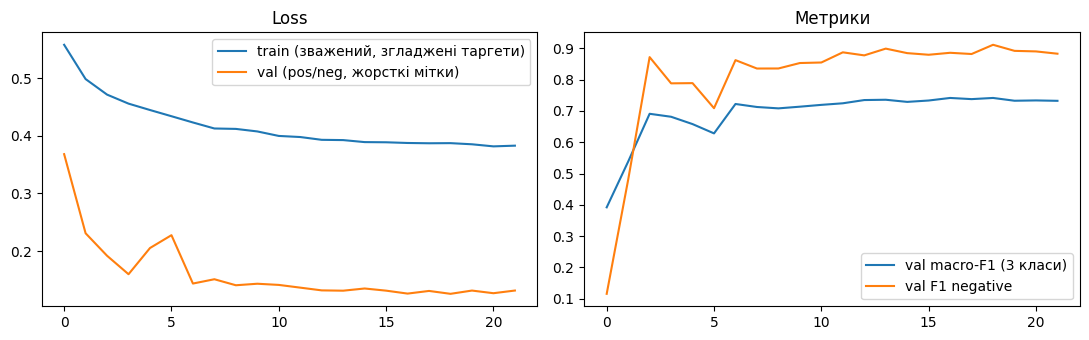

In [13]:
# ---------- ваги класів ----------
counts = np.bincount(train_ds.cls.numpy(), minlength=3)
cw = (counts.sum() / (3 * np.maximum(counts, 1))) ** WEIGHT_POWER
cw = cw / (cw * counts / counts.sum()).sum()                 # середня вага за вибіркою = 1
class_w = torch.tensor(cw, dtype=torch.float32, device=device)
print("counts :", dict(zip(CLASSES, counts.tolist())))
print("weights:", dict(zip(CLASSES, cw.round(2).tolist())))

# ---------- оптимізатор ----------
decay, no_decay = [], []
for n_, p_ in model.named_parameters():
    if not p_.requires_grad:
        continue
    (no_decay if p_.ndim < 2 or "embedding" in n_ else decay).append(p_)
optimizer = torch.optim.AdamW([{"params": decay, "weight_decay": WEIGHT_DECAY},
                               {"params": no_decay, "weight_decay": 0.0}], lr=LR)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=2)


@torch.no_grad()
def predict_p(model, loader):
    model.eval()
    return torch.cat([torch.sigmoid(model(x.to(device), l)).cpu() for x, l, _, _ in loader]).numpy()


def evaluate(model, loader, y_true, rule=SELECT_RULE):
    p = predict_p(model, loader)
    pred = assign_classes(p, rule)
    f = f1_score(y_true, pred, average=None, labels=[0, 1, 2], zero_division=0)
    m = y_true != 1                                           # pos/neg частина для loss
    y_pn, pp = (y_true[m] == 2).astype(int), p[m]
    eps = 1e-7
    return {
        "f1_3c": f.mean(), "f1_neg": f[0], "f1_neu": f[1], "f1_pos": f[2],
        "acc": accuracy_score(y_true, pred),
        "loss_pn": -np.mean(y_pn * np.log(pp + eps) + (1 - y_pn) * np.log(1 - pp + eps)),
    }, p


def train_epoch(model, loader, epoch):
    model.train()
    total, n = 0.0, 0
    pbar = tqdm(loader, desc=f"Epoch {epoch:02d} [train]", leave=False)
    for x, l, y, c in pbar:
        x, y, c = x.to(device), y.to(device), c.to(device)
        w = class_w[c]                                        # вага за узгодженим класом
        y_t = y * (1 - 2 * SMOOTH) + SMOOTH                   # згладжений таргет
        optimizer.zero_grad(set_to_none=True)
        loss = (F.binary_cross_entropy_with_logits(model(x, l), y_t, reduction="none") * w).mean()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
        optimizer.step()
        total += loss.item() * len(y)
        n += len(y)
        pbar.set_postfix(loss=f"{total / n:.4f}")
    return total / n


y_val = val_df["y_final"].values
history = {"train_loss": [], "val_loss_pn": [], "val_f1_3c": [], "val_f1_neg": []}
best_f1, best_state, bad_epochs = -1.0, None, 0

epoch_bar = tqdm(range(1, EPOCHS + 1), desc="Training")
for epoch in epoch_bar:
    tr = train_epoch(model, train_loader, epoch)
    val, _ = evaluate(model, val_loader, y_val)
    scheduler.step(val["f1_3c"])

    history["train_loss"].append(tr)
    history["val_loss_pn"].append(val["loss_pn"])
    history["val_f1_3c"].append(val["f1_3c"])
    history["val_f1_neg"].append(val["f1_neg"])
    epoch_bar.set_postfix(tr=f"{tr:.3f}", vl=f"{val['loss_pn']:.3f}", f1_3c=f"{val['f1_3c']:.3f}",
                          f1_neg=f"{val['f1_neg']:.2f}", lr=f"{optimizer.param_groups[0]['lr']:.1e}")

    if val["f1_3c"] > best_f1 + MIN_DELTA:
        best_f1, best_state, bad_epochs = val["f1_3c"], deepcopy(model.state_dict()), 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"Рання зупинка на епосі {epoch} (best val macro-F1 = {best_f1:.4f})")
            break

if best_state is None:
    best_state = deepcopy(model.state_dict())
model.load_state_dict(best_state)
print(f"Завантажено найкращу модель: val macro-F1 (3 класи) = {best_f1:.4f} | {describe_rule(SELECT_RULE)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(history["train_loss"], label="train (зважений, згладжені таргети)")
ax[0].plot(history["val_loss_pn"], label="val (pos/neg, жорсткі мітки)")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["val_f1_3c"], label="val macro-F1 (3 класи)")
ax[1].plot(history["val_f1_neg"], label="val F1 negative")
ax[1].set_title("Метрики"); ax[1].legend()
plt.tight_layout(); plt.show()

## 11. Правило класів
`fixed`: беремо `[NEUTRAL_LO, NEUTRAL_HI)` з конфігу. `tuned`: підбираємо межі на val за macro-F1. У будь-якому разі показуємо чутливість: macro-F1 на val для сусідніх меж.

In [14]:
p_val = predict_p(model, val_loader)


def macro_f1(pred):
    return f1_score(y_val, pred, average="macro", labels=[0, 1, 2], zero_division=0)


LO_GRID, HI_GRID = np.round(np.arange(0.05, 0.50, 0.025), 3), np.round(np.arange(0.50, 0.90, 0.025), 3)
asym_res = [(macro_f1(assign_classes(p_val, {"type": "asym", "lo": lo, "hi": hi})), lo, hi)
            for lo in LO_GRID for hi in HI_GRID]
best_asym = max(asym_res)
print(f"Найкращі межі на val: lo={best_asym[1]:.3f} hi={best_asym[2]:.3f}  macro-F1={best_asym[0]:.4f}")

if RULE_MODE == "tuned":
    RULE = {"type": "asym", "lo": float(best_asym[1]), "hi": float(best_asym[2])}
else:
    RULE = {"type": "asym", "lo": float(NEUTRAL_LO), "hi": float(NEUTRAL_HI)}
print(f"Обране правило ({RULE_MODE}):", describe_rule(RULE))
print(f"  val macro-F1 з обраним правилом = {macro_f1(assign_classes(p_val, RULE)):.4f} | "
      f"частка neutral: передбачено {(assign_classes(p_val, RULE) == 1).mean():.3f}, справжня {(y_val == 1).mean():.3f}")

sens = pd.DataFrame([{"lo": lo, "hi": hi, "macro-F1": f} for f, lo, hi in asym_res
                     if lo in (0.10, 0.15, 0.20, 0.25) and hi in (0.50, 0.55, 0.60, 0.65, 0.70)])
print("\nmacro-F1 на val (рядки lo, колонки hi):")
print(sens.pivot(index="lo", columns="hi", values="macro-F1").round(4))

Найкращі межі на val: lo=0.225 hi=0.625  macro-F1=0.7490
Обране правило (fixed): p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral
  val macro-F1 з обраним правилом = 0.7417 | частка neutral: передбачено 0.108, справжня 0.052

macro-F1 на val (рядки lo, колонки hi):
hi      0.50    0.55    0.60    0.65    0.70
lo                                          
0.10  0.7059  0.7325  0.7388  0.7409  0.7422
0.15  0.7065  0.7350  0.7417  0.7438  0.7452
0.20  0.7043  0.7351  0.7421  0.7444  0.7459
0.25  0.7042  0.7366  0.7439  0.7463  0.7478


## 12. Оцінка
Звіти val і test, діагностика train/val, наш незалежний тест `hand_test` та аналіз помилок.

===== VAL (мітки голосування) | p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral =====
Accuracy: 0.8901   Macro-F1: 0.7417

              precision    recall  f1-score   support

    negative      0.959     0.823     0.886       651
     neutral      0.282     0.583     0.380       103
    positive      0.966     0.952     0.959      1212

    accuracy                          0.890      1966
   macro avg      0.736     0.786     0.742      1966
weighted avg      0.928     0.890     0.905      1966

ROC AUC (OvR): {'negative': 0.984, 'neutral': 0.881, 'positive': 0.983} | macro = 0.950
ROC AUC pos vs neg (без нейтральних): 0.991



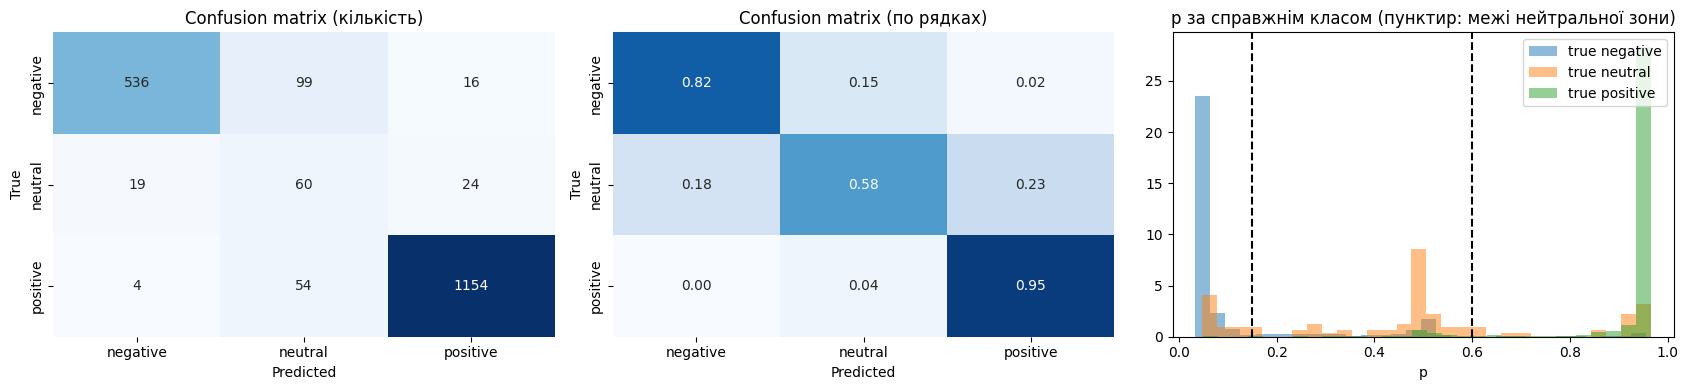

===== TEST (мітки голосування) | p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral =====
Accuracy: 0.8707   Macro-F1: 0.7270

              precision    recall  f1-score   support

    negative      0.958     0.802     0.873       651
     neutral      0.257     0.621     0.364       103
    positive      0.961     0.929     0.945      1211

    accuracy                          0.871      1965
   macro avg      0.725     0.784     0.727      1965
weighted avg      0.923     0.871     0.890      1965

ROC AUC (OvR): {'negative': 0.985, 'neutral': 0.876, 'positive': 0.98} | macro = 0.947
ROC AUC pos vs neg (без нейтральних): 0.991



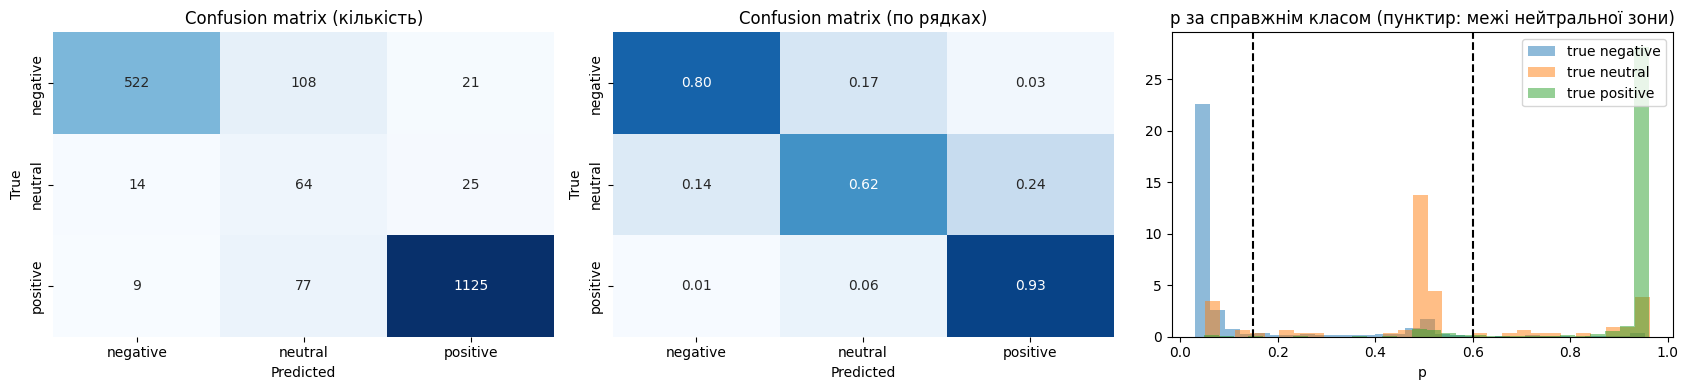

In [15]:
def predict_texts(texts, batch=256):
    return predict_texts_generic(model, stoi, texts, MAX_LEN, device, batch)


def predict(texts):
    # зручна обгортка для сирих фраз: чистить текст і видає p, H(p), клас
    cleaned = [clean_text(t) for t in texts]
    p = predict_texts(cleaned)
    return pd.DataFrame({"text": texts, "p": p.round(3), "H(p)": binary_entropy(p).round(3),
                         "class": [CLASSES[i] for i in assign_classes(p, RULE)]})


def rule_lines(ax, rule):
    lo, hi = rule_bounds(rule)
    ax.axvline(lo, color="k", ls="--"); ax.axvline(hi, color="k", ls="--")


def report_3class(p, y_true, rule, title="", plots=True):
    pred = assign_classes(p, rule)
    print(f"===== {title} | {describe_rule(rule)} =====")
    print(f"Accuracy: {accuracy_score(y_true, pred):.4f}   "
          f"Macro-F1: {f1_score(y_true, pred, average='macro', labels=[0, 1, 2], zero_division=0):.4f}\n")
    print(classification_report(y_true, pred, labels=[0, 1, 2], target_names=CLASSES, digits=3, zero_division=0))

    scores = {0: 1 - p, 1: binary_entropy(p), 2: p}
    try:
        aucs = {CLASSES[i]: roc_auc_score(y_true == i, scores[i]) for i in range(3)}
        print("ROC AUC (OvR):", {k: round(float(v), 3) for k, v in aucs.items()}, f"| macro = {np.mean(list(aucs.values())):.3f}")
        m = y_true != 1
        print(f"ROC AUC pos vs neg (без нейтральних): {roc_auc_score(y_true[m] == 2, p[m]):.3f}\n")
    except ValueError as e:
        print("AUC недоступний:", e)

    if plots:
        cm = confusion_matrix(y_true, pred, labels=[0, 1, 2])
        fig, ax = plt.subplots(1, 3, figsize=(17, 4))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
        ax[0].set(title="Confusion matrix (кількість)", xlabel="Predicted", ylabel="True")
        sns.heatmap(cm / np.maximum(cm.sum(1, keepdims=True), 1), annot=True, fmt=".2f", cmap="Blues",
                    xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], cbar=False, vmin=0, vmax=1)
        ax[1].set(title="Confusion matrix (по рядках)", xlabel="Predicted", ylabel="True")
        for i, c_ in enumerate(CLASSES):
            ax[2].hist(p[y_true == i], bins=30, alpha=0.5, density=True, label=f"true {c_}")
        rule_lines(ax[2], rule)
        ax[2].set(title="p за справжнім класом (пунктир: межі нейтральної зони)", xlabel="p"); ax[2].legend()
        plt.tight_layout(); plt.show()
    return pred


_ = report_3class(p_val, val_df["y_final"].values, RULE, "VAL (мітки голосування)")
p_test = predict_p(model, test_loader)
y_test = test_df["y_final"].values
_ = report_3class(p_test, y_test, RULE, "TEST (мітки голосування)")

p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral
          train    val  gap (train-val)
acc       0.969  0.890            0.079
macro_f1  0.928  0.742            0.186
f1_neg    0.980  0.886            0.094
f1_neu    0.819  0.380            0.440
f1_pos    0.984  0.959            0.025
prec_neg  0.999  0.959            0.041
rec_neg   0.962  0.823            0.139
auc_neg   0.999  0.984            0.015
auc_neu   0.991  0.881            0.110
auc_pos   0.998  0.983            0.015


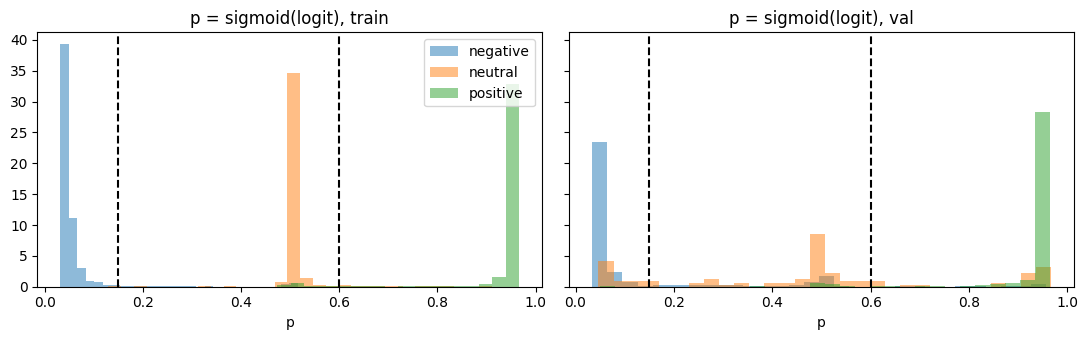

In [16]:
# ---------- train проти val: чи є переобучення ----------
def diag_metrics(p, y, rule):
    pred = assign_classes(p, rule)
    pr, rc, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2], zero_division=0)
    out = {"acc": accuracy_score(y, pred), "macro_f1": f.mean(),
           "f1_neg": f[0], "f1_neu": f[1], "f1_pos": f[2], "prec_neg": pr[0], "rec_neg": rc[0]}
    scores = {0: 1 - p, 1: binary_entropy(p), 2: p}
    for i, nm in enumerate(["auc_neg", "auc_neu", "auc_pos"]):
        out[nm] = roc_auc_score(y == i, scores[i])
    return out


p_train = predict_p(model, train_eval_loader)
y_train = train_df["y_final"].values
diag = pd.DataFrame({"train": diag_metrics(p_train, y_train, RULE), "val": diag_metrics(p_val, y_val, RULE)})
diag["gap (train-val)"] = diag["train"] - diag["val"]
print(describe_rule(RULE)); print(diag.round(3))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for a, p_, y_, nm in [(ax[0], p_train, y_train, "train"), (ax[1], p_val, y_val, "val")]:
    for i, c_ in enumerate(CLASSES):
        a.hist(p_[y_ == i], bins=30, alpha=0.5, density=True, label=c_)
    rule_lines(a, RULE)
    a.set_title(f"p = sigmoid(logit), {nm}"); a.set_xlabel("p")
ax[0].legend(); plt.tight_layout(); plt.show()

In [17]:
# ---------- наш незалежний тест: пари й шаблони, яких не було в train ----------
ph = predict_texts(hand_test[TEXT_COL].tolist())
ht = hand_test.assign(p=ph, pred=assign_classes(ph, RULE))
ht["y"] = ht["hand_y"].astype(int)
ht["ok"] = ht["pred"] == ht["y"]
print(f"hand_test: accuracy = {ht['ok'].mean():.3f} (n={len(ht)})")
print("за джерелом:", ht.groupby("src")["ok"].mean().round(3).to_dict())
print("за класами :", ht.groupby(ht["y"].map(names))["ok"].mean().round(3).to_dict())
print("середнє p за класами:", ht.groupby(ht["y"].map(names))["p"].mean().round(3).to_dict())
print("\nматриця (рядки = справжній, колонки = передбачений):")
print(pd.crosstab(ht["y"].map(names), ht["pred"].map(names)))

# пари: у кожній парі позитивна версія має отримати вищу p за нейтральну
pairs_ok = []
for pid, g in ht[ht["pair"].notna()].groupby("pair"):
    pp = g.groupby("y")["p"].mean()
    if 1 in pp.index and 2 in pp.index:
        pairs_ok.append(bool(pp[2] > pp[1]))
if pairs_ok:
    print(f"\nпари позитив/нейтраль: у {sum(pairs_ok)} з {len(pairs_ok)} p(позитив) > p(нейтраль)")

bad = ht[~ht["ok"]].sort_values("p")
for _, r in bad.head(12).iterrows():
    print(f"p={r.p:.2f} справжній={CLASSES[r.y][:3]} передбачено={CLASSES[r.pred][:3]} | {r[TEXT_COL][:110]}")

hand_test: accuracy = 0.982 (n=272)
за джерелом: {'hand_test': 0.583, 'syn_test': 1.0}
за класами : {'negative': 1.0, 'neutral': 0.989, 'positive': 0.957}
середнє p за класами: {'negative': 0.04500000178813934, 'neutral': 0.48500001430511475, 'positive': 0.9169999957084656}

матриця (рядки = справжній, колонки = передбачений):
pred      negative  neutral  positive
y                                    
negative        90        0         0
neutral          1       88         0
positive         2        2        89

пари позитив/нейтраль: у 1 з 5 p(позитив) > p(нейтраль)
p=0.07 справжній=pos передбачено=neg | it did not take long to set up and nothing went wrong during the first week of using it
p=0.08 справжній=pos передбачено=neg | nothing broke in shipping and the zipper does not get stuck like it did on the last bag i owned
p=0.09 справжній=neu передбачено=neg | nothing broke in shipping but the zipper gets stuck lot just like it did on the last bag
p=0.26 справжній=pos передбачено=n

In [18]:
# ---------- аналіз помилок на val ----------
view = val_df.assign(p=p_val, pred=assign_classes(p_val, RULE))
errs = view[view["pred"] != view["y_final"]]
print(f"Помилок: {len(errs)} з {len(view)} ({len(errs) / len(view):.1%})")

pairs_e = errs.groupby(["y_final", "pred"]).size().sort_values(ascending=False).head(3)
for (t_, p_), n_ in pairs_e.items():
    print(f"\n=== справжній {CLASSES[t_]} -> передбачено {CLASSES[p_]} (всього {n_}) ===")
    sub = errs[(errs.y_final == t_) & (errs.pred == p_)]
    for _, r in sub.sample(min(8, len(sub)), random_state=SEED).iterrows():
        v = "/".join(CLASSES[int(r[f"vote_{c}"])][:3] for c in QCOLS)
        print(f"p={r.p:.2f} голоси={v} | {r[TEXT_COL][:150]}")

Помилок: 216 з 1966 (11.0%)

=== справжній negative -> передбачено neutral (всього 99) ===
p=0.52 голоси=neu/neg/neg | the charge does not last long the light work then does not at times have it to my granddaughter she likes it enough
p=0.28 голоси=neg/neg/neg | there placement of backslash next to the enter key throws me off and keep hitting that key
p=0.20 голоси=neg/neg/neg | sound quality is horrific find speaker like the jbl extreme or that has stereo sound instead god awful even when plugged in with an aux connection ins
p=0.49 голоси=pos/neg/neg | it was great while it lasted this mouse has low profile it easy on the hands and eye pleasing white the internal battery holds charge well used it for
p=0.34 голоси=neu/neg/neg | i used two charge speakers in my workshop wish jbl could make it so both speakers will turn off and on when one turns bluetooth back on from the same 
p=0.50 голоси=neg/neg/neu | i been using the speaker for while and have not even charged it yet
p=0.50 голоси

In [19]:
# ---------- UMAP представлень (необов'язково, RUN_UMAP) ----------
if RUN_UMAP:
    import umap

    @torch.no_grad()
    def extract_features(model, loader):
        model.eval()
        store, feats = {}, []
        hook = model.fc.register_forward_hook(lambda m, inp, out: store.__setitem__("h", inp[0].detach().cpu()))
        for x, l, _, _ in loader:
            model(x.to(device), l)
            feats.append(store["h"])
        hook.remove()
        return torch.cat(feats).numpy()

    UMAP_N = 4000
    sel = np.random.RandomState(SEED).choice(len(val_df), size=min(UMAP_N, len(val_df)), replace=False)
    feats_val = extract_features(model, val_loader)[sel]
    emb2d = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1, metric="cosine", random_state=SEED).fit_transform(feats_val)

    y_u, pred_u = y_val[sel], assign_classes(p_val[sel], RULE)
    palette = {0: "#d62728", 1: "#9e9e9e", 2: "#2ca02c"}

    def scatter_cls(ax, labels, title):
        for i in [2, 1, 0]:
            m = labels == i
            ax.scatter(emb2d[m, 0], emb2d[m, 1], s=8, alpha=0.6, c=palette[i], label=f"{CLASSES[i]} ({m.sum()})")
        ax.set_title(title); ax.legend(markerscale=2); ax.set_xticks([]); ax.set_yticks([])

    fig, ax = plt.subplots(1, 3, figsize=(20, 6))
    scatter_cls(ax[0], y_u, "Узгоджені класи")
    scatter_cls(ax[1], pred_u, "Передбачення моделі")
    ok = pred_u == y_u
    ax[2].scatter(emb2d[ok, 0], emb2d[ok, 1], s=6, alpha=0.25, c="#bdbdbd", label=f"правильно ({ok.sum()})")
    for i in [2, 1, 0]:
        m = (~ok) & (y_u == i)
        ax[2].scatter(emb2d[m, 0], emb2d[m, 1], s=14, alpha=0.9, c=palette[i], edgecolors="k", linewidths=0.3,
                      label=f"помилка, справжній {CLASSES[i]} ({m.sum()})")
    ax[2].set_title("Помилки (колір = справжній клас)"); ax[2].legend(markerscale=1.5, fontsize=8)
    ax[2].set_xticks([]); ax[2].set_yticks([])
    plt.tight_layout(); plt.show()
else:
    print("UMAP пропущено (RUN_UMAP=False)")

UMAP пропущено (RUN_UMAP=False)


## 13. Експорт
У `artifacts/` лежить усе, що треба забрати з Colab:

| Файл | Призначення |
|------|-------------|
| `sentiment_rnn.pt` | модель + словник + правило + архітектура + очищення (один файл) |
| `config.yaml` | параметри, з якими навчено (для `configs/` у репозиторії) |
| `metrics.json` | метрики val, test, `hand_test` |
| `labeled.csv`, `hand_test.csv` | розмічені дані для навчання на сервері без трансформерів |
| `teacher_scores.csv` | кеш суддів |

Після збереження артефакт **завантажується назад** в окрему модель, і ми перевіряємо, що передбачення збігаються з тими, що в пам'яті.

In [20]:
CKPT_VERSION = 1


def export_artifact(path):
    ck = {
        "format_version": CKPT_VERSION,
        "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
        "itos": itos, "pad_idx": PAD_IDX, "unk_idx": UNK_IDX, "emb_dim": EMB_DIM, "max_len": MAX_LEN,
        "classes": CLASSES,
        "rule": RULE,
        "arch": ARCH,
        "cleaning": {"restore_neg": RESTORE_NEG, "neg_fragments": NEG_FRAGMENTS, "keep_single_char": ["i"]},
        "label_mode": LABEL_MODE,
    }
    torch.save(ck, path)
    return ck


def load_artifact(path, map_location="cpu"):
    ck = torch.load(path, map_location=map_location, weights_only=True)
    assert ck["format_version"] == CKPT_VERSION, "несумісна версія артефакту"
    emb0 = torch.zeros(len(ck["itos"]), ck["emb_dim"])          # справжні ваги прийдуть із state_dict
    m = BiRNNClassifier(emb0, pad_idx=ck["pad_idx"], **ck["arch"])
    m.load_state_dict(ck["state_dict"])
    return m.eval(), {w: i for i, w in enumerate(ck["itos"])}, ck


ckpt_path = os.path.join(OUT_DIR, ARTIFACT_NAME)
export_artifact(ckpt_path)
print(f"Збережено {ckpt_path}: {os.path.getsize(ckpt_path) / 1e6:.1f} МБ")

# ---------- перевірка: завантажуємо в окрему модель і порівнюємо передбачення ----------
m2, stoi2, ck2 = load_artifact(ckpt_path, map_location="cpu")
probe_texts = [clean_text(t) for t in ["doesn't have any flaws", "i will never buy this again",
                                       "great sound but the battery is bad", "works fine"]] + val_df[TEXT_COL].head(50).tolist()
p_mem = predict_texts(probe_texts)
p_ld = predict_texts_generic(m2, stoi2, probe_texts, ck2["max_len"], "cpu")
print("max |p_пам'ять - p_файл| =", float(np.abs(p_mem - p_ld).max()))
assert np.allclose(p_mem, p_ld, atol=1e-4), "завантажена модель дає інші p, експорт неповний"
print("Перевірка артефакту пройдена, правило:", describe_rule(ck2["rule"]))

Збережено artifacts/sentiment_rnn.pt: 20.0 МБ
max |p_пам'ять - p_файл| = 3.725290298461914e-07
Перевірка артефакту пройдена, правило: p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral


In [21]:
# ---------- конфіг і метрики ----------
cfg_out = {
    "seed": SEED, "classes": CLASSES, "artifact": ARTIFACT_NAME,
    "preprocessing": {"restore_neg": RESTORE_NEG, "max_len": MAX_LEN, "min_freq": MIN_FREQ},
    "model": {k: (list(v) if isinstance(v, tuple) else v) for k, v in ARCH.items()},
    "embeddings": {"name": EMB_NAME, "dim": EMB_DIM, "vocab_size": VOCAB_SIZE},
    "training": {"epochs": EPOCHS, "lr": LR, "weight_decay": WEIGHT_DECAY, "clip_norm": CLIP_NORM,
                 "patience": PATIENCE, "min_delta": MIN_DELTA, "weight_power": WEIGHT_POWER,
                 "smooth": SMOOTH, "batch_size": BATCH_SIZE, "scalar_target": {int(k): v for k, v in SCALAR_TARGET.items()}},
    "rule": {"type": RULE["type"], "lo": RULE.get("lo"), "hi": RULE.get("hi"), "mode": RULE_MODE},
    "labels": {"mode": LABEL_MODE, "vote_h_thr": VOTE_H_THR, "judges": TEACHER_MODELS},
}
try:
    import yaml
    text_cfg = yaml.safe_dump(cfg_out, allow_unicode=True, sort_keys=False)
except ImportError:
    text_cfg = json.dumps(cfg_out, indent=2, ensure_ascii=False)       # JSON теж коректний YAML
with open(os.path.join(OUT_DIR, "config.yaml"), "w") as f:
    f.write(text_cfg)


def split_metrics(p, y):
    pred = assign_classes(p, RULE)
    f = f1_score(y, pred, average=None, labels=[0, 1, 2], zero_division=0)
    m = y != 1
    return {"n": int(len(y)), "acc": round(float(accuracy_score(y, pred)), 4), "macro_f1": round(float(f.mean()), 4),
            "f1": {c: round(float(v), 4) for c, v in zip(CLASSES, f)},
            "auc_pos_vs_neg": round(float(roc_auc_score(y[m] == 2, p[m])), 4)}


metrics = {"val": split_metrics(p_val, y_val), "test": split_metrics(p_test, y_test),
           "hand_test": {"n": int(len(ht)), "acc": round(float(ht["ok"].mean()), 4),
                         "by_class": {k: round(float(v), 4) for k, v in ht.groupby(ht["y"].map(names))["ok"].mean().items()}},
           "rule": describe_rule(RULE)}
with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, ensure_ascii=False)
print(json.dumps(metrics, indent=2, ensure_ascii=False))

shutil.make_archive("artifacts", "zip", OUT_DIR)
print("\nФайли в", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))
try:
    from google.colab import files
    files.download("artifacts.zip")
except Exception:
    print("artifacts.zip створено поруч із ноутбуком")

{
  "val": {
    "n": 1966,
    "acc": 0.8901,
    "macro_f1": 0.7417,
    "f1": {
      "negative": 0.886,
      "neutral": 0.3797,
      "positive": 0.9593
    },
    "auc_pos_vs_neg": 0.9912
  },
  "test": {
    "n": 1965,
    "acc": 0.8707,
    "macro_f1": 0.727,
    "f1": {
      "negative": 0.8729,
      "neutral": 0.3636,
      "positive": 0.9446
    },
    "auc_pos_vs_neg": 0.9912
  },
  "hand_test": {
    "n": 272,
    "acc": 0.9816,
    "by_class": {
      "negative": 1.0,
      "neutral": 0.9888,
      "positive": 0.957
    }
  },
  "rule": "p < 0.150 -> neg, p >= 0.600 -> pos, між ними neutral"
}

Файли в artifacts : ['config.yaml', 'hand_test.csv', 'labeled.csv', 'metrics.json', 'sentiment_rnn.pt', 'teacher_scores.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14. Інтерактив (необов'язково)
Установи `INTERACTIVE = True` у конфігу. Вердикт моделі та SHAP для довільних фраз. Тексти чистяться тією ж `clean_text`.

In [22]:
if INTERACTIVE:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

    EXPLAIN = True          # False -> лише вердикт без SHAP
    TEXTS = []              # заповни список або лишай порожнім для вводу з клавіатури
    VERDICT = {"negative": "НЕГАТИВНИЙ", "neutral": "НЕЙТРАЛЬНИЙ / неоднозначний", "positive": "ПОЗИТИВНИЙ"}

    def f_prob(texts):
        # SHAP викликає це на текстах із «замаскованими» словами; маска "..." clean_text просто вилучає
        return predict_texts([clean_text(t) for t in texts])

    _shap_explainer = shap.Explainer(f_prob, shap.maskers.Text(r"\s+"), algorithm="partition")

    def shap_explain(text):
        # внесок кожного слова у p(позитив): >0 тягне до позитиву, <0 до негативу
        base = float(f_prob([""])[0])
        words = text.split()
        if len(words) < 2:
            vals = np.array([float(f_prob([text])[0]) - base])      # для одного слова це точне значення Шеплі
        else:
            sv = _shap_explainer([text])[0]
            words = [w.strip() for w in sv.data]
            vals = np.asarray(sv.values, dtype=float).reshape(len(words), -1)[:, 0]
            base = float(np.ravel(sv.base_values)[0])
        print(f"  база (текст без слів) p = {base:.3f}  ->  сума внесків {vals.sum():+.3f}  ->  p = {base + vals.sum():.3f}")
        print("  внесок слів:  " + "  ".join(f"{w}({v:+.3f})" for w, v in zip(words, vals) if abs(v) >= 0.003))
        fig, ax = plt.subplots(figsize=(max(5, 0.45 * len(words) + 2), 2.8))
        ax.bar(range(len(words)), vals, color=["#2ca02c" if v > 0 else "#d62728" for v in vals])
        ax.axhline(0, color="k", lw=0.6)
        lim = max(0.25, 1.1 * np.abs(vals).max())
        ax.set_ylim(-lim, lim)
        ax.set_xticks(range(len(words))); ax.set_xticklabels(words, rotation=60, ha="right")
        ax.set_ylabel("внесок у p(позитив)"); ax.set_title("SHAP: що тягне вердикт")
        plt.tight_layout(); plt.show()

    def verdict(raw_text):
        text = clean_text(raw_text)
        toks = text.split()[:MAX_LEN]
        if not toks:
            print("  (після очищення нічого не лишилось)\n")
            return
        p = float(predict_texts([text])[0])
        cls = CLASSES[int(assign_classes(np.array([p]), RULE)[0])]
        oov = sum(w not in stoi for w in toks) / len(toks)
        print(f"  очищено : {text}")
        print(f"  p(позитив) = {p:.3f} | H(p) = {float(binary_entropy(p)):.3f} | невідомих слів: {oov:.0%}")
        print(f"  ВЕРДИКТ : {VERDICT[cls]}")
        if oov > 0.5:
            print("  ! багато невідомих моделі слів: вердикт ненадійний")
        if EXPLAIN:
            shap_explain(text)
        print()

    for t in TEXTS:
        print(">", t)
        verdict(t)
    if not TEXTS:
        while True:
            t = input("Текст (порожній рядок — вийти): ").strip()
            if not t:
                break
            verdict(t)
else:
    print("Інтерактив вимкнено (INTERACTIVE=False)")

Інтерактив вимкнено (INTERACTIVE=False)
